In [1]:
# Inspect the columns and data types in the monthly dataset
import duckdb

# Create an in-memory DuckDB connection
con = duckdb.connect()

# Read the Parquet schema without loading the full dataset
con.execute("""
    DESCRIBE SELECT *
    FROM read_parquet('../data/processed/monthly.parquet')
""").df()

,column_name,column_type,null,key,default,extra
0,LCLid,VARCHAR,YES,None,None,None
1,month,DATE,YES,None,None,None
2,tariff,VARCHAR,YES,None,None,None
3,acorn,VARCHAR,YES,None,None,None
4,acorn_group,VARCHAR,YES,None,None,None
5,days,BIGINT,YES,None,None,None
6,kwh,DOUBLE,YES,None,None,None
7,bill_gbp,DOUBLE,YES,None,None,None
8,temp_mean,DOUBLE,YES,None,None,None
9,filled_slots,DOUBLE,YES,None,None,None


In [2]:
# Summarize the size and time coverage of the monthly dataset
summary = con.execute("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT LCLid) AS total_households,
        MIN(month) AS first_month,
        MAX(month) AS last_month,
        COUNT(DISTINCT month) AS months_covered
    FROM read_parquet('../data/processed/monthly.parquet')
""").df()

# Display the dataset summary
display(summary)

,total_records,total_households,first_month,last_month,months_covered
0,106225,5548,2011-12-01,2014-01-01,26


In [3]:
# Calculate descriptive statistics for the monthly numerical features
stats = con.execute("""
    SUMMARIZE
    SELECT
        days,
        kwh,
        bill_gbp,
        temp_mean,
        filled_slots
    FROM read_parquet('../data/processed/monthly.parquet')
""").df()

# Display the descriptive statistics
display(stats)

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,days,BIGINT,28,31,4,30.499458696163803,0.7518129596298598,30,31,31,106225,0.0
1,kwh,DOUBLE,0.20400000000000007,6385.8940013,122302,310.96084560149575,254.84910145131022,156.39000042476485,247.5326921964999,383.26729614803054,106225,0.0
2,bill_gbp,DOUBLE,0.029025120000000005,908.584998504964,108418,44.24350911218041,36.25993015449227,22.25116926043556,35.21895144571799,54.53127089594179,106225,0.0
3,temp_mean,DOUBLE,3.8005357142857155,20.03909946236559,32,11.013479805615018,5.0448978869074885,7.0299569110642235,10.960981182795699,14.95051388888889,106225,0.0
4,filled_slots,DOUBLE,0.0,146.0,131,2.2877571193221935,12.783271362887147,0.0,0.0,0.0,106225,0.0


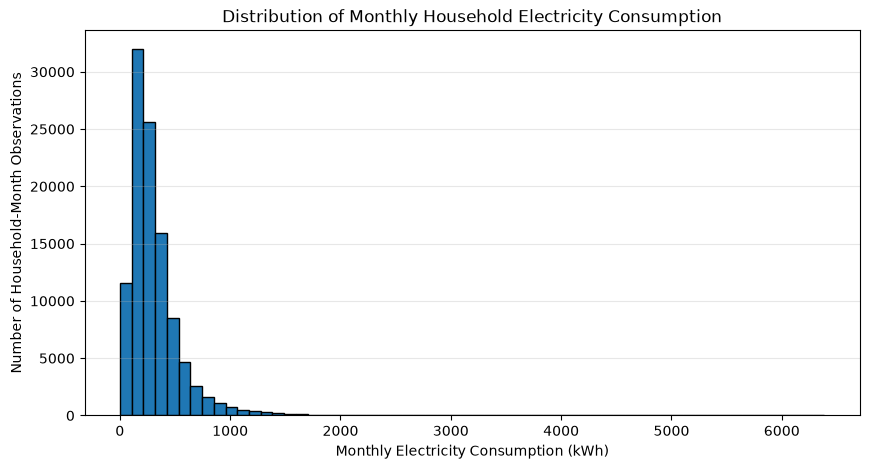

In [5]:
# Visualize the distribution of monthly electricity consumption
import matplotlib.pyplot as plt

# Retrieve monthly consumption values using DuckDB
consumption = con.execute("""
    SELECT kwh
    FROM read_parquet('../data/processed/monthly.parquet')
""").df()

# Plot the consumption distribution
plt.figure(figsize=(10, 5))
plt.hist(consumption["kwh"], bins=60, edgecolor="black")

plt.title("Distribution of Monthly Household Electricity Consumption")
plt.xlabel("Monthly Electricity Consumption (kWh)")
plt.ylabel("Number of Household-Month Observations")
plt.grid(axis="y", alpha=0.3)
# Save the histogram for the Phase 3 report
plt.savefig("../reports/monthly_consumption_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

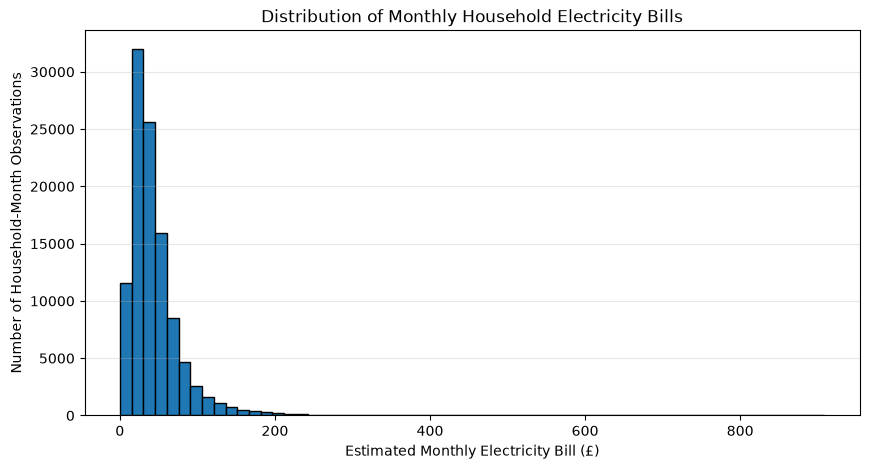

In [6]:
# Visualize the distribution of estimated monthly electricity bills
import matplotlib.pyplot as plt

# Retrieve monthly electricity bill values from DuckDB
bills = con.execute("""
    SELECT bill_gbp
    FROM read_parquet('../data/processed/monthly.parquet')
""").df()

# Create a histogram of monthly bills
plt.figure(figsize=(10, 5))
plt.hist(bills["bill_gbp"], bins=60, edgecolor="black")

plt.title("Distribution of Monthly Household Electricity Bills")
plt.xlabel("Estimated Monthly Electricity Bill (£)")
plt.ylabel("Number of Household-Month Observations")
plt.grid(axis="y", alpha=0.3)

# Save the chart for the Phase 3 report
plt.savefig("../reports/phase3/monthly_bill_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

Examine the relationship between consumption and electricity bills
Next, we'll use a scatter plot to investigate the relationship between kwh and bill_gbp.

Because there are 106,225 observations, we'll plot a reproducible sample of 10,000 observations to keep the visualization readable.

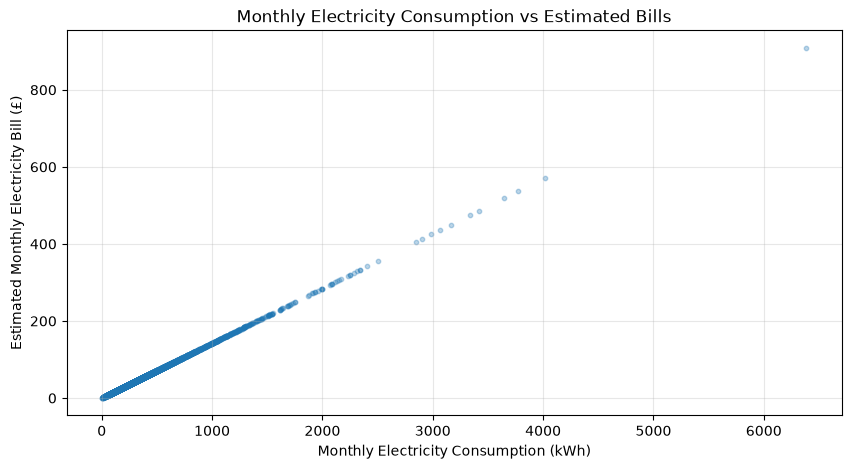

In [7]:
# Examine the relationship between monthly consumption and estimated bills
import matplotlib.pyplot as plt

# Retrieve a reproducible sample of household-month observations
relationship = con.execute("""
    SELECT kwh, bill_gbp
    FROM read_parquet('../data/processed/monthly.parquet')
    ORDER BY hash(LCLid, month)
    LIMIT 10000
""").df()

# Plot electricity consumption against estimated bills
plt.figure(figsize=(10, 5))
plt.scatter(
    relationship["kwh"],
    relationship["bill_gbp"],
    alpha=0.3,
    s=10
)

plt.title("Monthly Electricity Consumption vs Estimated Bills")
plt.xlabel("Monthly Electricity Consumption (kWh)")
plt.ylabel("Estimated Monthly Electricity Bill (£)")
plt.grid(alpha=0.3)

# Save the scatter plot in the Phase 3 folder
plt.savefig("../reports/phase3/consumption_vs_bill.png", dpi=300, bbox_inches="tight")
plt.show()

Examine monthly electricity consumption trends
Next, we'll investigate whether electricity consumption changes over time.

This will help us identify seasonal patterns that may be useful for forecasting.

We'll calculate the average household consumption for each calendar month across the dataset.

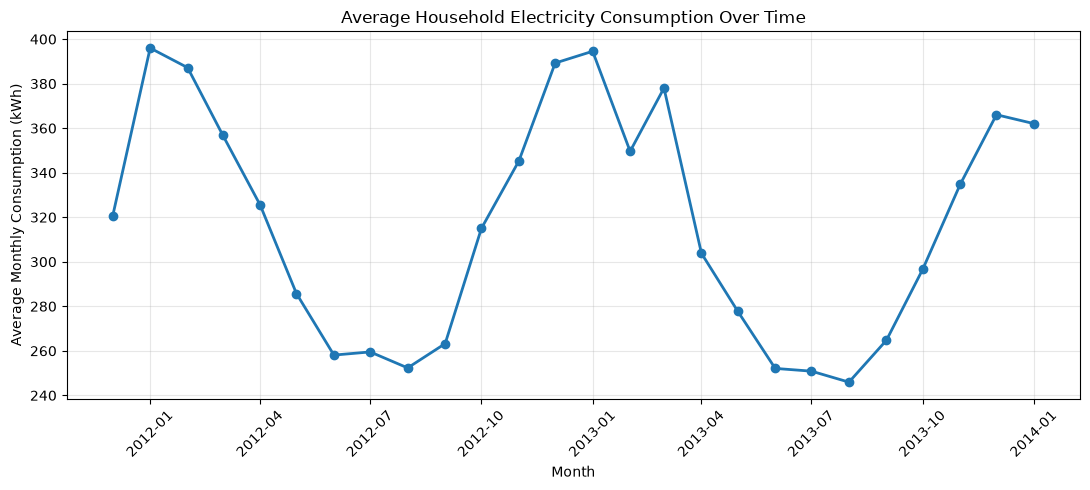

In [8]:
# Analyze average monthly electricity consumption over time
import matplotlib.pyplot as plt

# Aggregate household consumption by calendar month
monthly_trend = con.execute("""
    SELECT
        month,
        AVG(kwh) AS avg_kwh,
        COUNT(*) AS household_records
    FROM read_parquet('../data/processed/monthly.parquet')
    GROUP BY month
    ORDER BY month
""").df()

# Plot the monthly consumption trend
plt.figure(figsize=(11, 5))
plt.plot(
    monthly_trend["month"],
    monthly_trend["avg_kwh"],
    marker="o",
    linewidth=2
)

plt.title("Average Household Electricity Consumption Over Time")
plt.xlabel("Month")
plt.ylabel("Average Monthly Consumption (kWh)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the visualization for the Phase 3 report
plt.savefig("../reports/phase3/monthly_consumption_trend.png", dpi=300, bbox_inches="tight")
plt.show()

Examine the relationship between temperature and electricity consumption
Our previous chart suggests that electricity consumption may be influenced by seasonal weather conditions.

Next, we'll examine whether monthly average temperature is associated with electricity consumption.

We'll aggregate the data by month because the temperature values may be shared across households within the same period. This avoids displaying thousands of repeated temperature observations.

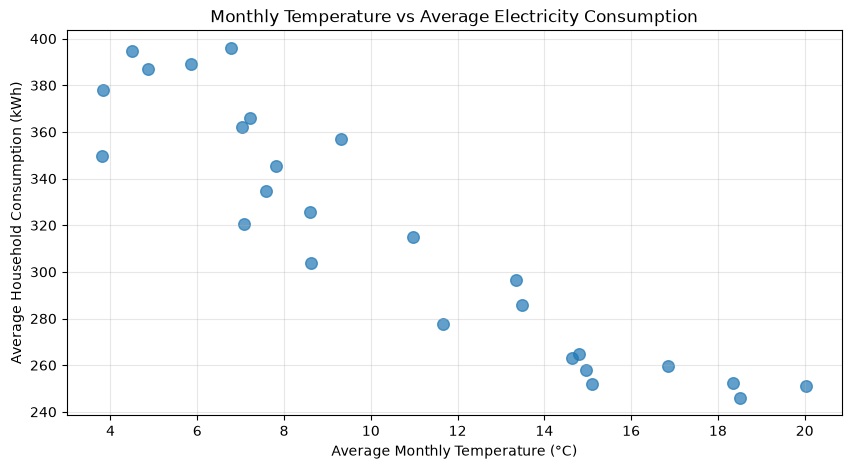

In [9]:
# Examine the relationship between temperature and electricity consumption
import matplotlib.pyplot as plt

# Calculate average temperature and consumption for each month
temperature_data = con.execute("""
    SELECT
        month,
        AVG(temp_mean) AS avg_temperature,
        AVG(kwh) AS avg_consumption
    FROM read_parquet('../data/processed/monthly.parquet')
    GROUP BY month
    ORDER BY month
""").df()

# Plot monthly temperature against average consumption
plt.figure(figsize=(10, 5))
plt.scatter(
    temperature_data["avg_temperature"],
    temperature_data["avg_consumption"],
    s=70,
    alpha=0.7
)

plt.title("Monthly Temperature vs Average Electricity Consumption")
plt.xlabel("Average Monthly Temperature (°C)")
plt.ylabel("Average Household Consumption (kWh)")
plt.grid(alpha=0.3)

# Save the visualization for the Phase 3 report
plt.savefig("../reports/phase3/temperature_vs_consumption.png",
            dpi=300, bbox_inches="tight")
plt.show()

Quantify the temperature–consumption relationship
We have visually identified a negative relationship. Next, let's calculate the Pearson correlation coefficient to measure its strength.

We'll use the 26 monthly aggregated observations shown in the scatter plot, rather than treating repeated household-level temperature values as independent observations.

In [10]:
# Calculate the correlation between monthly temperature and consumption

# Measure the linear relationship using the 26 monthly observations
temperature_correlation = con.execute("""
    WITH monthly_summary AS (
        SELECT
            month,
            AVG(temp_mean) AS avg_temperature,
            AVG(kwh) AS avg_consumption
        FROM read_parquet('../data/processed/monthly.parquet')
        GROUP BY month
    )
    SELECT
        COUNT(*) AS months_analyzed,
        CORR(avg_temperature, avg_consumption) AS pearson_correlation
    FROM monthly_summary
""").df()

# Display the correlation result
display(temperature_correlation)

,months_analyzed,pearson_correlation
0,26,-0.921251


Examine correlations among numerical variables
Next, we'll generate a correlation heatmap to investigate relationships among the numerical attributes in monthly.parquet.

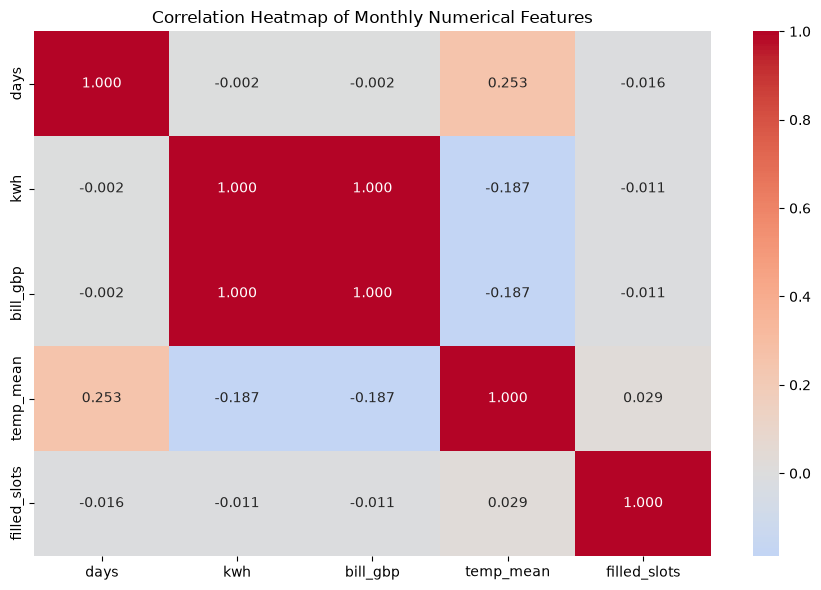

In [11]:
# Calculate and visualize correlations among monthly numerical variables
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve the numerical features using DuckDB
numeric_data = con.execute("""
    SELECT
        days,
        kwh,
        bill_gbp,
        temp_mean,
        filled_slots
    FROM read_parquet('../data/processed/monthly.parquet')
""").df()

# Calculate the Pearson correlation matrix
correlation_matrix = numeric_data.corr()

# Display the correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Monthly Numerical Features")
plt.tight_layout()

# Save the heatmap for the Phase 3 report
plt.savefig("../reports/phase3/numerical_correlation_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()

Examine electricity consumption outliers
Our earlier histogram revealed a long right tail, with some household-month observations exceeding 6,000 kWh.

Next, we'll use a box plot to examine the distribution and identify potential outliers.

We'll also calculate the interquartile range (IQR) thresholds in a later step to quantify their prevalence.

C:\Users\edehi\AppData\Local\Temp\ipykernel_52564\1926019636.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


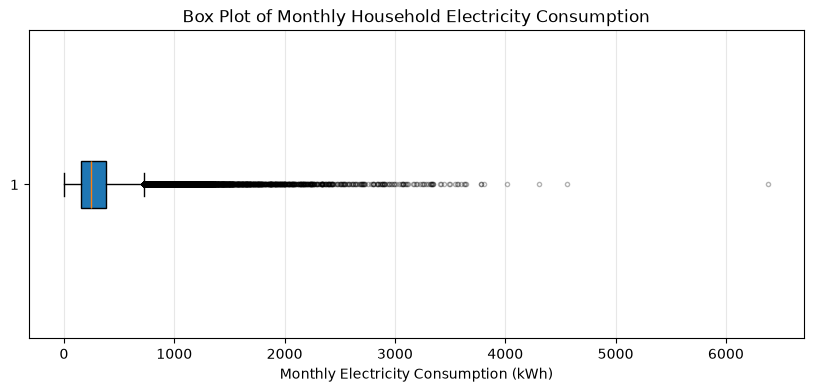

In [12]:
# Visualize potential outliers in monthly electricity consumption
import matplotlib.pyplot as plt

# Use the consumption values retrieved earlier
plt.figure(figsize=(10, 4))

# Create a horizontal box plot
plt.boxplot(
    consumption["kwh"],
    vert=False,
    patch_artist=True,
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.3}
)

plt.title("Box Plot of Monthly Household Electricity Consumption")
plt.xlabel("Monthly Electricity Consumption (kWh)")
plt.grid(axis="x", alpha=0.3)

# Save the box plot in the Phase 3 folder
plt.savefig(
    "../reports/phase3/monthly_consumption_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Quantify consumption outliers using the IQR method

Next, we'll calculate the exact IQR boundaries and determine how many household-month observations fall outside them.

In [13]:
# Calculate IQR thresholds and count potential consumption outliers
outlier_summary = con.execute("""
    WITH quartiles AS (
        SELECT
            QUANTILE_CONT(kwh, 0.25) AS q1,
            QUANTILE_CONT(kwh, 0.75) AS q3
        FROM read_parquet('../data/processed/monthly.parquet')
    ),
    boundaries AS (
        SELECT
            q1,
            q3,
            q3 - q1 AS iqr,
            q1 - 1.5 * (q3 - q1) AS lower_bound,
            q3 + 1.5 * (q3 - q1) AS upper_bound
        FROM quartiles
    )
    SELECT
        ROUND(b.q1, 2) AS q1,
        ROUND(b.q3, 2) AS q3,
        ROUND(b.iqr, 2) AS iqr,
        ROUND(b.lower_bound, 2) AS lower_bound,
        ROUND(b.upper_bound, 2) AS upper_bound,
        COUNT(*) AS total_records,
        COUNT(*) FILTER (
            WHERE m.kwh < b.lower_bound OR m.kwh > b.upper_bound
        ) AS outlier_count,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE m.kwh < b.lower_bound OR m.kwh > b.upper_bound
            ) / COUNT(*), 2
        ) AS outlier_percentage
    FROM read_parquet('../data/processed/monthly.parquet') AS m
    CROSS JOIN boundaries AS b
    GROUP BY b.q1, b.q3, b.iqr, b.lower_bound, b.upper_bound
""").df()

# Display the IQR boundaries and outlier statistics
display(outlier_summary)

,q1,q3,iqr,lower_bound,upper_bound,total_records,outlier_count,outlier_percentage
0,156.43,383.2,226.77,-183.73,723.36,106225,5802,5.46


Examine consumption differences across tariff categories

Next, we'll investigate whether households in different tariff categories exhibit different consumption patterns.

This is relevant because tariff information may influence the calculation of electricity bills and could also be associated with household consumption behavior.

We'll first examine the number of observations, households, and average consumption within each tariff category.

In [14]:
# Summarize electricity consumption by tariff category
tariff_summary = con.execute("""
    SELECT
        tariff,
        COUNT(*) AS total_records,
        COUNT(DISTINCT LCLid) AS households,
        ROUND(AVG(kwh), 2) AS avg_kwh,
        ROUND(MEDIAN(kwh), 2) AS median_kwh,
        ROUND(AVG(bill_gbp), 2) AS avg_bill_gbp
    FROM read_parquet('../data/processed/monthly.parquet')
    GROUP BY tariff
    ORDER BY total_records DESC
""").df()

# Display the tariff-level summary statistics
display(tariff_summary)

,tariff,total_records,households,avg_kwh,median_kwh,avg_bill_gbp
0,Std,84807,4428,315.96,250.29,44.95
1,ToU,21418,1120,291.16,236.81,41.43


Visualize electricity consumption by tariff category

A box plot will help us compare the distributions of consumption between the two tariff groups, including their medians, variability, and high-consumption observations.

We'll retain the full consumption range rather than exclude outliers.

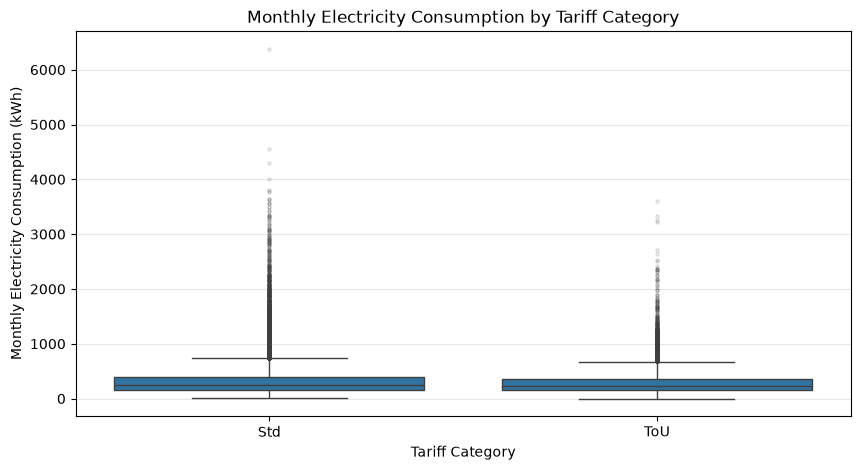

In [15]:
# Compare monthly electricity consumption across tariff categories
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve tariff categories and monthly consumption
tariff_data = con.execute("""
    SELECT tariff, kwh
    FROM read_parquet('../data/processed/monthly.parquet')
""").df()

# Create a box plot for each tariff category
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=tariff_data,
    x="tariff",
    y="kwh",
    order=["Std", "ToU"],
    flierprops={"marker": "o", "markersize": 2, "alpha": 0.2}
)

plt.title("Monthly Electricity Consumption by Tariff Category")
plt.xlabel("Tariff Category")
plt.ylabel("Monthly Electricity Consumption (kWh)")
plt.grid(axis="y", alpha=0.3)

# Save the chart in the Phase 3 folder
plt.savefig(
    "../reports/phase3/consumption_by_tariff.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Examine consumption across ACORN household groups

Our dataset includes acorn and acorn_group, which represent household socioeconomic classifications.

These variables may help explain differences in electricity consumption between household groups.

We'll begin by summarizing consumption across the broader acorn_group categories.

In [16]:
# Summarize electricity consumption across ACORN household groups
acorn_summary = con.execute("""
    SELECT
        acorn_group,
        COUNT(*) AS total_records,
        COUNT(DISTINCT LCLid) AS households,
        ROUND(AVG(kwh), 2) AS avg_kwh,
        ROUND(MEDIAN(kwh), 2) AS median_kwh,
        ROUND(AVG(bill_gbp), 2) AS avg_bill_gbp
    FROM read_parquet('../data/processed/monthly.parquet')
    GROUP BY acorn_group
    ORDER BY avg_kwh DESC
""").df()

# Display the household group summary
display(acorn_summary)

,acorn_group,total_records,households,avg_kwh,median_kwh,avg_bill_gbp
0,Unknown,867,49,366.77,248.05,52.18
1,Affluent,42652,2188,352.60,262.93,50.17
2,Comfortable,28385,1501,306.72,262.62,43.64
3,Adversity,34321,1810,261.31,221.85,37.18


Visualize electricity consumption across ACORN groups

Next, we'll create a bar chart comparing average monthly consumption across the identified ACORN groups.

We'll include the Unknown group for transparency, but distinguish it from the classified groups when interpreting the chart.

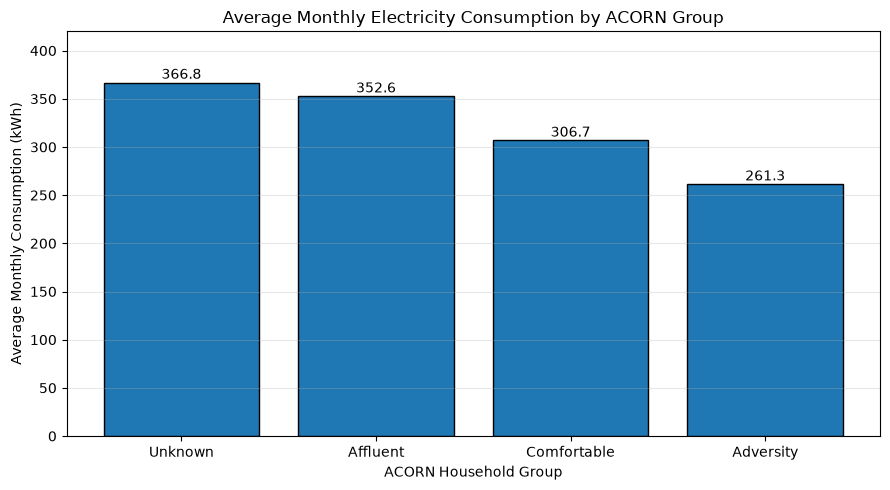

In [17]:
# Compare average monthly electricity consumption across ACORN groups
import matplotlib.pyplot as plt

# Use the ACORN summary calculated in Step 16
plot_data = acorn_summary.sort_values("avg_kwh", ascending=False)

# Create a bar chart of average consumption
plt.figure(figsize=(9, 5))
bars = plt.bar(
    plot_data["acorn_group"],
    plot_data["avg_kwh"],
    edgecolor="black"
)

# Display average consumption above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 4,
        f"{bar.get_height():.1f}",
        ha="center"
    )

plt.title("Average Monthly Electricity Consumption by ACORN Group")
plt.xlabel("ACORN Household Group")
plt.ylabel("Average Monthly Consumption (kWh)")
plt.ylim(0, 420)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save the chart in the Phase 3 folder
plt.savefig(
    "../reports/phase3/consumption_by_acorn_group.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Inspect the existing encoded dataset

We have now examined several important relationships in monthly.parquet, including consumption distributions, seasonal trends, temperature associations, tariff differences, and ACORN classifications.

In [18]:
# Inspect the columns and data types in the encoded monthly dataset

# Retrieve the schema without loading the entire Parquet file
encoded_schema = con.execute("""
    DESCRIBE SELECT *
    FROM read_parquet('../data/processed/monthly_encoded.parquet')
""").df()

# Display the encoded dataset schema
display(encoded_schema)

,column_name,column_type,null,key,default,extra
0,LCLid,VARCHAR,YES,None,None,None
1,month,DATE,YES,None,None,None
2,tariff,VARCHAR,YES,None,None,None
3,acorn,VARCHAR,YES,None,None,None
4,acorn_group,VARCHAR,YES,None,None,None
5,days,BIGINT,YES,None,None,None
6,kwh,DOUBLE,YES,None,None,None
7,bill_gbp,DOUBLE,YES,None,None,None
8,temp_mean,DOUBLE,YES,None,None,None
9,filled_slots,DOUBLE,YES,None,None,None


In [19]:
# Validate the size and binary indicators in the encoded dataset

encoded_validation = con.execute("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT LCLid) AS households,
        MIN(tariff_tou) AS min_tariff_tou,
        MAX(tariff_tou) AS max_tariff_tou,
        SUM(tariff_tou) AS tou_records,
        SUM(
            acorn_affluent +
            acorn_comfortable +
            acorn_adversity +
            acorn_unknown
        ) AS acorn_indicator_total
    FROM read_parquet('../data/processed/monthly_encoded.parquet')
""").df()

# Display the validation results
display(encoded_validation)

,total_records,households,min_tariff_tou,max_tariff_tou,tou_records,acorn_indicator_total
0,106225,5548,0,1,21418.0,106225.0


Check household history before feature engineering

We are now ready to begin developing features for electricity bill forecasting.

Our first candidate is previous-month electricity consumption, which could be useful because households often have recurring consumption patterns.

However, before creating lagged features, we should check how much historical data is available for each household.

This is important because our dataset contains 26 calendar months, but not every household necessarily has observations for all 26 months.

In [20]:
# Examine the number of monthly observations available per household

# Count monthly records for each household
household_coverage = con.execute("""
    WITH household_counts AS (
        SELECT
            LCLid,
            COUNT(*) AS months_available
        FROM read_parquet('../data/processed/monthly_encoded.parquet')
        GROUP BY LCLid
    )
    SELECT
        MIN(months_available) AS min_months,
        ROUND(AVG(months_available), 2) AS avg_months,
        MEDIAN(months_available) AS median_months,
        MAX(months_available) AS max_months,
        COUNT(*) AS total_households
    FROM household_counts
""").df()

# Display the household coverage statistics
display(household_coverage)

,min_months,avg_months,median_months,max_months,total_households
0,1,19.15,20.0,26,5548


Check for gaps in household monthly records

Before creating lagged consumption features, let's determine how frequently households have gaps in their monthly histories.

In [21]:
# Identify gaps between consecutive household monthly observations

# Compare each observation with the previous available month
monthly_gaps = con.execute("""
    WITH ordered_months AS (
        SELECT
            LCLid,
            month,
            LAG(month) OVER (
                PARTITION BY LCLid
                ORDER BY month
            ) AS previous_month
        FROM read_parquet('../data/processed/monthly_encoded.parquet')
    )
    SELECT
        COUNT(*) FILTER (
            WHERE previous_month IS NOT NULL
        ) AS consecutive_pairs_checked,

        COUNT(*) FILTER (
            WHERE previous_month IS NOT NULL
              AND month = previous_month + INTERVAL '1 month'
        ) AS adjacent_month_pairs,

        COUNT(*) FILTER (
            WHERE previous_month IS NOT NULL
              AND month > previous_month + INTERVAL '1 month'
        ) AS pairs_with_gaps

    FROM ordered_months
""").df()

# Display the monthly continuity results
display(monthly_gaps)

,consecutive_pairs_checked,adjacent_month_pairs,pairs_with_gaps
0,100677,100385,292


Create the previous-month consumption feature

We'll now create our first engineered feature, previous_month_kwh.

This feature will represent a household's electricity consumption during the calendar month immediately preceding the target month.

We will use DuckDB's LAG() window function and explicitly check calendar-month continuity.

For now, we'll display a small sample rather than save a new Parquet file. This lets us validate the feature before incorporating it into our engineered dataset.

In [22]:
# Create previous-month consumption using each household's history

previous_month_sample = con.execute("""
    WITH monthly_history AS (
        SELECT
            LCLid,
            month,
            kwh,

            -- Retrieve the previous available observation
            LAG(month) OVER (
                PARTITION BY LCLid ORDER BY month
            ) AS prior_month,

            LAG(kwh) OVER (
                PARTITION BY LCLid ORDER BY month
            ) AS prior_kwh

        FROM read_parquet('../data/processed/monthly_encoded.parquet')
    )
    SELECT
        LCLid,
        month,
        kwh,

        -- Use the previous value only for adjacent calendar months
        CASE
            WHEN prior_month = month - INTERVAL '1 month'
            THEN prior_kwh
            ELSE NULL
        END AS previous_month_kwh

    FROM monthly_history
    ORDER BY LCLid, month
    LIMIT 15
""").df()

# Display a sample of the engineered feature
display(previous_month_sample)

,LCLid,month,kwh,previous_month_kwh
0,MAC000002,2012-11-01,357.06454,NaN
1,MAC000002,2012-12-01,355.64150,357.06454
2,MAC000002,2013-01-01,359.87200,355.64150
3,MAC000002,2013-02-01,381.62200,359.87200
4,MAC000002,2013-03-01,479.68400,381.62200
5,MAC000002,2013-04-01,362.58800,479.68400
6,MAC000002,2013-05-01,303.89400,362.58800
7,MAC000002,2013-06-01,299.93100,303.89400
8,MAC000002,2013-07-01,271.15100,299.93100
9,MAC000002,2013-08-01,269.89100,271.15100


Measure previous-month feature availability

Before creating more features, let's quantify how many observations have a valid previous_month_kwh value.

This will tell us how much historical information is available for forecasting across the entire dataset.

In [23]:
# Measure the availability of previous-month consumption for all households
feature_availability = con.execute("""
    WITH monthly_history AS (
        SELECT
            LCLid,
            month,
            LAG(month) OVER (
                PARTITION BY LCLid ORDER BY month
            ) AS prior_month
        FROM read_parquet('../data/processed/monthly_encoded.parquet')
    )
    SELECT
        COUNT(*) AS total_records,
        COUNT(*) FILTER (
            WHERE prior_month = month - INTERVAL '1 month'
        ) AS records_with_history,
        COUNT(*) FILTER (
            WHERE prior_month IS NULL
               OR prior_month <> month - INTERVAL '1 month'
        ) AS records_without_history,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE prior_month = month - INTERVAL '1 month'
            ) / COUNT(*), 2
        ) AS history_availability_pct
    FROM monthly_history
""").df()

# Display the feature availability summary
display(feature_availability)

,total_records,records_with_history,records_without_history,history_availability_pct
0,106225,100385,5840,94.5


Engineer a three-month rolling consumption average

Our next feature is rolling_3month_kwh.

It represents the average electricity consumption over the three calendar months immediately preceding the prediction month.

For example, when forecasting April 2013, we would use January, February, and March 2013 consumption.

This feature may help capture a household's recent consumption pattern while reducing the influence of unusually high or low consumption in any single month.

We must ensure that all three preceding calendar months exist. Otherwise, the rolling average will be NULL.

In [24]:
# Calculate the average consumption over three preceding calendar months

rolling_sample = con.execute("""
    WITH monthly_history AS (
        SELECT
            LCLid,
            month,
            kwh,
            LAG(month, 1) OVER w AS month_1,
            LAG(month, 2) OVER w AS month_2,
            LAG(month, 3) OVER w AS month_3,
            LAG(kwh, 1) OVER w AS kwh_1,
            LAG(kwh, 2) OVER w AS kwh_2,
            LAG(kwh, 3) OVER w AS kwh_3
        FROM read_parquet('../data/processed/monthly_encoded.parquet')
        WINDOW w AS (PARTITION BY LCLid ORDER BY month)
    )
    SELECT
        LCLid,
        month,
        kwh,
        CASE
            WHEN month_1 = month - INTERVAL '1 month'
             AND month_2 = month - INTERVAL '2 months'
             AND month_3 = month - INTERVAL '3 months'
            THEN ROUND((kwh_1 + kwh_2 + kwh_3) / 3.0, 2)
            ELSE NULL
        END AS rolling_3month_kwh
    FROM monthly_history
    ORDER BY LCLid, month
    LIMIT 15
""").df()

# Display the rolling consumption feature
display(rolling_sample)

,LCLid,month,kwh,rolling_3month_kwh
0,MAC000002,2012-11-01,357.06454,NaN
1,MAC000002,2012-12-01,355.64150,NaN
2,MAC000002,2013-01-01,359.87200,NaN
3,MAC000002,2013-02-01,381.62200,357.53
4,MAC000002,2013-03-01,479.68400,365.71
5,MAC000002,2013-04-01,362.58800,407.06
6,MAC000002,2013-05-01,303.89400,407.96
7,MAC000002,2013-06-01,299.93100,382.06
8,MAC000002,2013-07-01,271.15100,322.14
9,MAC000002,2013-08-01,269.89100,291.66


Measure three-month rolling feature availability

We previously established that previous_month_kwh is available for 94.50% of observations.

The three-month rolling average requires more historical data, so we expect its availability to be lower.

Let's measure how many observations have three complete, consecutive preceding calendar months.

In [25]:
# Measure availability of three-month historical consumption

rolling_availability = con.execute("""
    WITH monthly_history AS (
        SELECT
            LCLid,
            month,
            LAG(month, 1) OVER w AS month_1,
            LAG(month, 2) OVER w AS month_2,
            LAG(month, 3) OVER w AS month_3
        FROM read_parquet('../data/processed/monthly_encoded.parquet')
        WINDOW w AS (PARTITION BY LCLid ORDER BY month)
    ),
    feature_check AS (
        SELECT
            CASE
                WHEN month_1 = month - INTERVAL '1 month'
                 AND month_2 = month - INTERVAL '2 months'
                 AND month_3 = month - INTERVAL '3 months'
                THEN 1
                ELSE 0
            END AS has_rolling_history
        FROM monthly_history
    )
    SELECT
        COUNT(*) AS total_records,
        SUM(has_rolling_history) AS records_with_history,
        COUNT(*) - SUM(has_rolling_history) AS records_without_history,
        ROUND(
            100.0 * SUM(has_rolling_history) / COUNT(*), 2
        ) AS rolling_availability_pct
    FROM feature_check
""").df()

# Display the rolling feature availability
display(rolling_availability)

,total_records,records_with_history,records_without_history,rolling_availability_pct
0,106225,88947.0,17278.0,83.73


Engineer calendar and seasonal features

Our earlier exploratory analysis identified a recurring seasonal pattern: average electricity consumption was generally higher during winter and lower during summer.

We can represent this pattern using calendar features derived from the month column.

Unlike historical consumption features, calendar information is known in advance, making it particularly useful for forecasting.

In [26]:
# Create calendar and seasonal features from the observation month

calendar_sample = con.execute("""
    SELECT
        LCLid,
        month,
        MONTH(month) AS month_number,
        QUARTER(month) AS quarter,
        CASE
            WHEN MONTH(month) IN (12, 1, 2) THEN 'Winter'
            WHEN MONTH(month) IN (3, 4, 5) THEN 'Spring'
            WHEN MONTH(month) IN (6, 7, 8) THEN 'Summer'
            ELSE 'Autumn'
        END AS season
    FROM read_parquet('../data/processed/monthly_encoded.parquet')
    ORDER BY LCLid, month
    LIMIT 15
""").df()

# Display the engineered calendar features
display(calendar_sample)

,LCLid,month,month_number,quarter,season
0,MAC000002,2012-11-01,11,4,Autumn
1,MAC000002,2012-12-01,12,4,Winter
2,MAC000002,2013-01-01,1,1,Winter
3,MAC000002,2013-02-01,2,1,Winter
4,MAC000002,2013-03-01,3,1,Spring
5,MAC000002,2013-04-01,4,2,Spring
6,MAC000002,2013-05-01,5,2,Spring
7,MAC000002,2013-06-01,6,2,Summer
8,MAC000002,2013-07-01,7,3,Summer
9,MAC000002,2013-08-01,8,3,Summer


Examine electricity consumption by season

Before finalizing our seasonal features, let's quantify the differences in electricity consumption across the four seasons.

In [27]:
# Summarize electricity consumption across the four seasons

seasonal_summary = con.execute("""
    WITH seasonal_data AS (
        SELECT
            kwh,
            CASE
                WHEN MONTH(month) IN (12, 1, 2) THEN 'Winter'
                WHEN MONTH(month) IN (3, 4, 5) THEN 'Spring'
                WHEN MONTH(month) IN (6, 7, 8) THEN 'Summer'
                ELSE 'Autumn'
            END AS season
        FROM read_parquet('../data/processed/monthly_encoded.parquet')
    )
    SELECT
        season,
        COUNT(*) AS observations,
        ROUND(AVG(kwh), 2) AS avg_kwh,
        ROUND(MEDIAN(kwh), 2) AS median_kwh,
        ROUND(STDDEV_SAMP(kwh), 2) AS std_kwh
    FROM seasonal_data
    GROUP BY season
    ORDER BY CASE season
        WHEN 'Winter' THEN 1
        WHEN 'Spring' THEN 2
        WHEN 'Summer' THEN 3
        ELSE 4
    END
""").df()

# Display the seasonal consumption statistics
display(seasonal_summary)

,season,observations,avg_kwh,median_kwh,std_kwh
0,Winter,27384,373.13,290.19,314.44
1,Spring,20144,318.34,251.62,259.11
2,Summer,28176,252.64,214.14,175.49
3,Autumn,30521,304.15,246.89,240.64


Create a seasonal consumption visualization

Although we already have a monthly consumption trend chart, a seasonal box plot will help illustrate both the differences in typical consumption and the variation within each season.

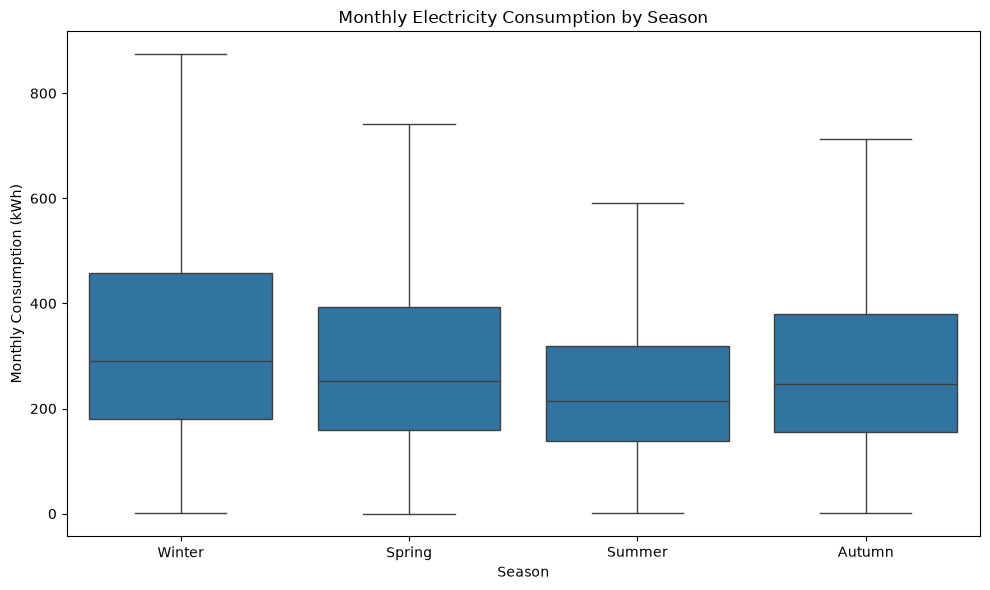

In [28]:
# Visualize the distribution of monthly electricity consumption by season

import matplotlib.pyplot as plt
import seaborn as sns

seasonal_plot_data = con.execute("""
    SELECT
        kwh,
        CASE
            WHEN MONTH(month) IN (12, 1, 2) THEN 'Winter'
            WHEN MONTH(month) IN (3, 4, 5) THEN 'Spring'
            WHEN MONTH(month) IN (6, 7, 8) THEN 'Summer'
            ELSE 'Autumn'
        END AS season
    FROM read_parquet('../data/processed/monthly_encoded.parquet')
""").df()

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=seasonal_plot_data,
    x="season",
    y="kwh",
    order=["Winter", "Spring", "Summer", "Autumn"],
    showfliers=False
)

plt.title("Monthly Electricity Consumption by Season")
plt.xlabel("Season")
plt.ylabel("Monthly Consumption (kWh)")
plt.tight_layout()

plt.savefig(
    "../reports/phase3/consumption_by_season.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Encode the seasonal feature

We previously created the categorical season feature. However, most machine learning models require categorical values to be represented numerically.

We'll use one-hot encoding, consistent with the approach already used for the ACORN categories.

This produces four binary indicators:

Feature	Meaning
season_winter	1 if winter, otherwise 0
season_spring	1 if spring, otherwise 0
season_summer	1 if summer, otherwise 0
season_autumn	1 if autumn, otherwise 0

In [29]:
# Encode meteorological seasons as binary indicator features

season_encoded_sample = con.execute("""
    SELECT
        LCLid,
        month,
        CASE WHEN MONTH(month) IN (12, 1, 2)
            THEN 1 ELSE 0 END AS season_winter,
        CASE WHEN MONTH(month) IN (3, 4, 5)
            THEN 1 ELSE 0 END AS season_spring,
        CASE WHEN MONTH(month) IN (6, 7, 8)
            THEN 1 ELSE 0 END AS season_summer,
        CASE WHEN MONTH(month) IN (9, 10, 11)
            THEN 1 ELSE 0 END AS season_autumn
    FROM read_parquet('../data/processed/monthly_encoded.parquet')
    ORDER BY LCLid, month
    LIMIT 15
""").df()

# Display the encoded seasonal features
display(season_encoded_sample)

,LCLid,month,season_winter,season_spring,season_summer,season_autumn
0,MAC000002,2012-11-01,0,0,0,1
1,MAC000002,2012-12-01,1,0,0,0
2,MAC000002,2013-01-01,1,0,0,0
3,MAC000002,2013-02-01,1,0,0,0
4,MAC000002,2013-03-01,0,1,0,0
5,MAC000002,2013-04-01,0,1,0,0
6,MAC000002,2013-05-01,0,1,0,0
7,MAC000002,2013-06-01,0,0,1,0
8,MAC000002,2013-07-01,0,0,1,0
9,MAC000002,2013-08-01,0,0,1,0


Consolidate the engineered features

We are ready to combine the validated features into a single dataset.

To preserve the Phase 2 outputs, we'll create a new Parquet file:

data/processed/monthly_features.parquet

This will contain the original encoded monthly dataset plus the newly engineered historical and calendar features.

We'll retain kwh and bill_gbp for analysis and target construction, but current-month kwh must not be used as an input when predicting that same month's bill. Likewise, observed current-month temperature and data-quality fields will require availability checks before modeling.

In [30]:
# Consolidate historical and calendar features into a new Parquet dataset

con.execute("""
    COPY (
        WITH history AS (
            SELECT
                *,
                LAG(month, 1) OVER w AS month_1,
                LAG(month, 2) OVER w AS month_2,
                LAG(month, 3) OVER w AS month_3,
                LAG(kwh, 1) OVER w AS kwh_1,
                LAG(kwh, 2) OVER w AS kwh_2,
                LAG(kwh, 3) OVER w AS kwh_3
            FROM read_parquet('../data/processed/monthly_encoded.parquet')
            WINDOW w AS (PARTITION BY LCLid ORDER BY month)
        )
        SELECT
            * EXCLUDE (
                month_1, month_2, month_3,
                kwh_1, kwh_2, kwh_3
            ),

            CASE
                WHEN month_1 = month - INTERVAL '1 month'
                THEN kwh_1
                ELSE NULL
            END AS previous_month_kwh,

            CASE
                WHEN month_1 = month - INTERVAL '1 month'
                 AND month_2 = month - INTERVAL '2 months'
                 AND month_3 = month - INTERVAL '3 months'
                THEN (kwh_1 + kwh_2 + kwh_3) / 3.0
                ELSE NULL
            END AS rolling_3month_kwh,

            MONTH(month) AS month_number,
            QUARTER(month) AS quarter,

            CASE WHEN MONTH(month) IN (12, 1, 2)
                THEN 1 ELSE 0 END AS season_winter,
            CASE WHEN MONTH(month) IN (3, 4, 5)
                THEN 1 ELSE 0 END AS season_spring,
            CASE WHEN MONTH(month) IN (6, 7, 8)
                THEN 1 ELSE 0 END AS season_summer,
            CASE WHEN MONTH(month) IN (9, 10, 11)
                THEN 1 ELSE 0 END AS season_autumn

        FROM history
    )
    TO '../data/processed/monthly_features.parquet'
    (FORMAT PARQUET)
""")

print("Feature-engineered dataset created successfully.")

Feature-engineered dataset created successfully.


In [31]:
# Validate the saved feature-engineered dataset

features_validation = con.execute("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT LCLid) AS total_households,
        COUNT(*) - COUNT(previous_month_kwh) AS missing_previous_month,
        COUNT(*) - COUNT(rolling_3month_kwh) AS missing_rolling_3month,
        COUNT(*) FILTER (
            WHERE season_winter + season_spring
                + season_summer + season_autumn <> 1
        ) AS invalid_season_records
    FROM read_parquet('../data/processed/monthly_features.parquet')
""").df()

feature_columns = con.execute("""
    DESCRIBE SELECT *
    FROM read_parquet('../data/processed/monthly_features.parquet')
""").df()

print("Total columns:", len(feature_columns))
display(features_validation)

Total columns: 23


,total_records,total_households,missing_previous_month,missing_rolling_3month,invalid_season_records
0,106225,5548,5840,17278,0


Review feature selection and target leakage

Before scaling any features, we need to distinguish between variables that can legitimately predict a future electricity bill and variables that would introduce information unavailable at prediction time.

For our project, the target variable is bill_gbp.

Let's first confirm the complete saved schema before deciding whether scaling is appropriate.

In [32]:
# Inspect all columns and data types in the engineered dataset

feature_schema = con.execute("""
    DESCRIBE SELECT *
    FROM read_parquet('../data/processed/monthly_features.parquet')
""").df()

print("Total columns:", len(feature_schema))
display(feature_schema[["column_name", "column_type"]])

Total columns: 23


,column_name,column_type
0,LCLid,VARCHAR
1,month,DATE
2,tariff,VARCHAR
3,acorn,VARCHAR
4,acorn_group,VARCHAR
5,days,BIGINT
6,kwh,DOUBLE
7,bill_gbp,DOUBLE
8,temp_mean,DOUBLE
9,filled_slots,DOUBLE


Examine the distributions of historical consumption features

Before deciding on a scaling method, let's inspect the descriptive statistics for our two historical consumption features.

This will help us understand their ranges, variability, and potential outliers.

In [33]:
# Summarize the distributions of engineered historical consumption features

historical_feature_stats = con.execute("""
    SELECT
        'previous_month_kwh' AS feature,
        COUNT(previous_month_kwh) AS valid_records,
        ROUND(AVG(previous_month_kwh), 2) AS mean,
        ROUND(MEDIAN(previous_month_kwh), 2) AS median,
        ROUND(STDDEV_SAMP(previous_month_kwh), 2) AS std_dev,
        ROUND(MIN(previous_month_kwh), 2) AS minimum,
        ROUND(MAX(previous_month_kwh), 2) AS maximum
    FROM read_parquet('../data/processed/monthly_features.parquet')

    UNION ALL

    SELECT
        'rolling_3month_kwh',
        COUNT(rolling_3month_kwh),
        ROUND(AVG(rolling_3month_kwh), 2),
        ROUND(MEDIAN(rolling_3month_kwh), 2),
        ROUND(STDDEV_SAMP(rolling_3month_kwh), 2),
        ROUND(MIN(rolling_3month_kwh), 2),
        ROUND(MAX(rolling_3month_kwh), 2)
    FROM read_parquet('../data/processed/monthly_features.parquet')
""").df()

# Display the historical feature statistics
display(historical_feature_stats)

,feature,valid_records,mean,median,std_dev,minimum,maximum
0,previous_month_kwh,100385,308.64,245.97,251.39,0.2,6385.89
1,rolling_3month_kwh,88947,306.87,247.47,240.56,4.7,3540.41


Check the relationship between historical features and the target

We have established that both historical consumption features are available for a substantial proportion of observations.

Our next task is to examine whether they have meaningful statistical relationships with the monthly electricity bill.

We'll calculate the Pearson correlation between:
- previous_month_kwh and bill_gbp
- rolling_3month_kwh and bill_gbp
Unlike the near-perfect correlation between current-month consumption and its calculated bill, these historical correlations will provide a more useful preliminary indication of forecasting potential.

In [34]:
# Examine correlations between historical consumption features and monthly bills

historical_correlations = con.execute("""
    SELECT
        ROUND(
            CORR(previous_month_kwh, bill_gbp), 4
        ) AS previous_month_bill_corr,

        ROUND(
            CORR(rolling_3month_kwh, bill_gbp), 4
        ) AS rolling_3month_bill_corr

    FROM read_parquet('../data/processed/monthly_features.parquet')
""").df()

# Display the correlation results
display(historical_correlations)

,previous_month_bill_corr,rolling_3month_bill_corr
0,0.9278,0.8781


Compare correlations using the same observations

Before drawing a firm conclusion about which historical feature has the stronger relationship with monthly bills, we should address one limitation of the previous analysis.

The previous-month feature is available for 100,385 observations, while the rolling-average feature is available for only 88,947.

A fairer comparison uses the same household-month observations for both correlations.

In [35]:
# Compare historical feature correlations on the same observations

comparable_correlations = con.execute("""
    SELECT
        COUNT(*) AS common_records,

        ROUND(
            CORR(previous_month_kwh, bill_gbp), 4
        ) AS previous_month_bill_corr,

        ROUND(
            CORR(rolling_3month_kwh, bill_gbp), 4
        ) AS rolling_3month_bill_corr,

        ROUND(
            CORR(previous_month_kwh, rolling_3month_kwh), 4
        ) AS historical_features_corr

    FROM read_parquet('../data/processed/monthly_features.parquet')

    WHERE previous_month_kwh IS NOT NULL
      AND rolling_3month_kwh IS NOT NULL
""").df()

# Display correlations calculated on common observations
display(comparable_correlations)

,common_records,previous_month_bill_corr,rolling_3month_bill_corr,historical_features_corr
0,88947,0.9263,0.8781,0.9574


Examine correlations within individual households

One limitation remains: the correlations calculated so far combine observations from different households.

A strong overall correlation may partly reflect the fact that some households consistently consume more electricity than others.

To investigate whether previous-month consumption is also informative within individual households, we'll calculate a correlation separately for each household.

We will restrict this analysis to households with at least six valid previous-month observations, providing a modest minimum history for each correlation calculation.

In [36]:
# Examine previous-month consumption correlations within individual households

household_correlations = con.execute("""
    WITH household_stats AS (
        SELECT
            LCLid,
            COUNT(previous_month_kwh) AS valid_months,
            CORR(previous_month_kwh, bill_gbp) AS correlation
        FROM read_parquet('../data/processed/monthly_features.parquet')
        GROUP BY LCLid
    )
    SELECT
        COUNT(*) AS households_analyzed,
        ROUND(AVG(correlation), 4) AS mean_correlation,
        ROUND(MEDIAN(correlation), 4) AS median_correlation,
        ROUND(MIN(correlation), 4) AS min_correlation,
        ROUND(MAX(correlation), 4) AS max_correlation,
        COUNT(*) FILTER (
            WHERE correlation > 0
        ) AS positive_correlations,
        COUNT(*) FILTER (
            WHERE correlation < 0
        ) AS negative_correlations
    FROM household_stats
    WHERE valid_months >= 6
      AND correlation IS NOT NULL
""").df()

# Display the household-level correlation summary
display(household_correlations)

,households_analyzed,mean_correlation,median_correlation,min_correlation,max_correlation,positive_correlations,negative_correlations
0,5474,0.5151,0.575,-0.7465,0.9923,5177,297


Examine the distribution of household correlations

Before completing our historical feature analysis, a histogram will help us visualize how the correlations vary across households.

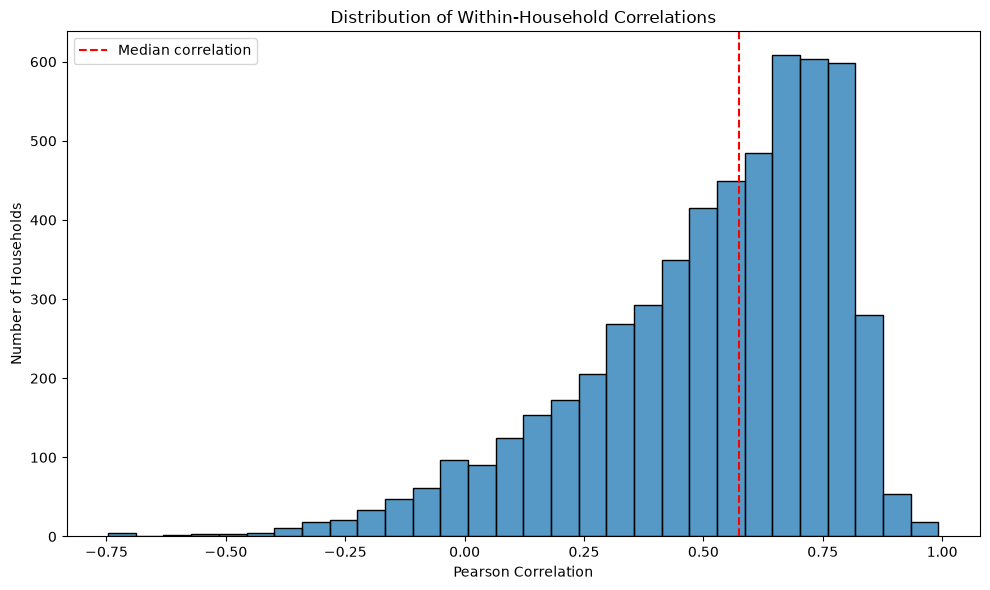

In [37]:
# Visualize within-household correlations between historical consumption and bills

household_corr_data = con.execute("""
    SELECT
        LCLid,
        CORR(previous_month_kwh, bill_gbp) AS correlation
    FROM read_parquet('../data/processed/monthly_features.parquet')
    GROUP BY LCLid
    HAVING COUNT(previous_month_kwh) >= 6
       AND CORR(previous_month_kwh, bill_gbp) IS NOT NULL
""").df()

plt.figure(figsize=(10, 6))

sns.histplot(
    data=household_corr_data,
    x="correlation",
    bins=30,
    edgecolor="black"
)

plt.axvline(
    household_corr_data["correlation"].median(),
    color="red",
    linestyle="--",
    label="Median correlation"
)

plt.title("Distribution of Within-Household Correlations")
plt.xlabel("Pearson Correlation")
plt.ylabel("Number of Households")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../reports/phase3/household_correlation_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Verify household-month uniqueness

A data integrity check

In [38]:
# Check for duplicate household-month records in the engineered dataset

duplicate_check = con.execute("""
    WITH household_month_counts AS (
        SELECT
            LCLid,
            month,
            COUNT(*) AS record_count
        FROM read_parquet('../data/processed/monthly_features.parquet')
        GROUP BY LCLid, month
    )
    SELECT
        COUNT(*) FILTER (
            WHERE record_count > 1
        ) AS duplicate_household_month_groups,

        COALESCE(
            SUM(record_count - 1) FILTER (
                WHERE record_count > 1
            ), 0
        ) AS excess_duplicate_records

    FROM household_month_counts
""").df()

# Display the duplicate check results
display(duplicate_check)

,duplicate_household_month_groups,excess_duplicate_records
0,0,0.0
